# Vèdere Beyond — Sales & Marketing Analytics

**End-to-end analysis of 14 months of operations (Sep 2024 – Oct 2025)** for Vèdere Beyond, an independent clothing brand.

| Business question | Section |
|---|---|
| How is revenue trending, and what drives it? | 3 |
| What does it cost to acquire a customer, and is it worth it? | 4 |
| Which Meta campaigns, strategies and creatives earn their budget? | 5 |
| Do customers come back? | 6 |
| Which products make the money? | 7 |
| Where should the next dollar of ad spend go? | 8 |

> **About the data.** The dataset is *synthetic*, generated by `scripts/01_generate_data.py` and calibrated to the brand's real headline figures (≈ $20K+ revenue, 240+ customers, 2.5–3.0× ROAS). Order-level details, customer identities and campaign-level splits are simulated; they are realistic but not actual brand records.

**Pipeline:** `01_generate_data` → `02_clean_transform` → `03_build_database` (SQLite) → `04_run_analysis` (SQL) → `05_export_tableau` → this notebook.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

from vb_analytics import ROOT, connect, run_query, sql, reallocation_plan, campaign_actions

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
con = connect()

# ---- chart styling: thin marks, recessive grid, fixed categorical order ----
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
GOOD, CRITICAL, MUTED = "#0ca30c", "#d03b3b", "#b8b6ae"
INK, INK2, INK3, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK3, "ytick.color": INK3, "legend.frameon": False, "figure.dpi": 110,
})
money = mtick.FuncFormatter(lambda v, _: f"${v:,.0f}")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 1. Data generation & cleaning

The raw exports deliberately reproduce the problems of real Shopify / Meta Ads Manager exports. `02_clean_transform.py` fixes them and logs every step:

In [2]:
print((ROOT / "data/processed/cleaning_log.txt").read_text())
raw = {p.stem: pd.read_csv(p, keep_default_na=False) for p in sorted((ROOT / "data/raw").glob("*.csv"))}
proc = {p.stem: pd.read_csv(p) for p in sorted((ROOT / "data/processed").glob("*.csv"))}
display(pd.DataFrame({"raw rows": {k: len(v) for k, v in raw.items()},
                      "processed rows": {"customers": len(proc["customers"]), "orders": len(proc["orders"]),
                                         "order_items": len(proc["order_items"]), "products": len(proc["products"]),
                                         "meta_campaigns": len(proc["ad_campaigns"]),
                                         "meta_ads_daily": len(proc["ad_performance_daily"])}}))

products: 15 SKUs, prices parsed from currency strings
meta ads: 1,232 campaign-day rows, 3,983 blank metric cells filled with 0
customers: removed 5 exact duplicate rows
orders: removed 6 duplicate rows
orders: removed 3 test / voided orders
orders: parsed 25 US-format (MM/DD/YYYY) timestamps
order_items: removed 4 zero-quantity lines
customers: 21 skipped the survey -> channel inferred from first-order UTM
reconciliation: Meta purchase value matches Shopify net sales for every campaign



,raw rows,processed rows
customers,260,255
meta_ads_daily,1232,1232
meta_campaigns,10,10
order_items,529,525
orders,361,352
products,15,15


A few examples of what the raw data looked like before cleaning:

In [3]:
o = raw["orders"]
display(o[o.created_at.str.contains("/") | o.name.str.startswith("#T")].head(5)[
    ["name", "email", "created_at", "financial_status", "subtotal", "utm_source", "utm_campaign"]])
c = raw["customers"]
display(c[(c.email != c.email.str.strip().str.lower()) | (c.how_did_you_hear == "")].head(5)[
    ["customer_id", "email", "state", "how_did_you_hear"]])

,name,email,created_at,financial_status,subtotal,utm_source,utm_campaign
12,#1013,avagutierrez57@hotmail.com,09/22/2024 21:36,paid,$90.00,instagram,launch_broad
20,#1021,ashley.phillips@outlook.com,10/01/2024 08:04,paid,$32.00,instagram,launch_broad
26,#1027,kimberly.james@gmail.com,10/10/2024 12:06,refunded,$32.00,facebook,retargeting_always_on
35,#1036,ashley.phillips@outlook.com,10/23/2024 17:53,paid,$62.00,,
48,#1049,sharon_c71@gmail.com,11/16/2024 08:00,paid,$32.00,,


,customer_id,email,state,how_did_you_hear
15,VB-C1188,REBECCAJIMENEZ63@GMAIL.COM,tx,Pop-up Event
16,VB-C1068,TCAMPBELL@HOTMAIL.COM,PA,Instagram
17,VB-C1143,jalen_r18@yahoo.com,PA,instagram ad
24,VB-C1180,joshua_p19@gmail.com,TX,
25,VB-C1149,ronald.jones@gmail.com,TN,


### Data model (SQLite: `data/vedere_beyond.db`)

| Table | Grain | Key fields |
|---|---|---|
| `customers` | customer | acquisition channel / campaign, cohort month, lifetime value |
| `orders` | order | net sales, discounts, COGS, fulfillment, fees, contribution margin, attribution |
| `order_items` | order line | product, size, quantity, price, unit cost |
| `products` | SKU | category, collection, price, unit cost, margin |
| `ad_campaigns` | Meta campaign | strategy, audience, creative type, funnel stage |
| `ad_performance_daily` | campaign × day | spend, impressions, clicks, ATC, purchases, purchase value |

Views: `v_order_lines` (discount-allocated line revenue), `v_campaign_performance`, `v_monthly_kpis`. All analysis queries live in `sql/analysis/`.

In [4]:
display(sql("SELECT name, type FROM sqlite_master WHERE type IN ('table','view') ORDER BY type, name", con))

,name,type
0,ad_campaigns,table
1,ad_performance_daily,table
2,customers,table
3,order_items,table
4,orders,table
5,products,table
6,v_campaign_performance,view
7,v_monthly_kpis,view
8,v_order_lines,view


## 2. Headline KPIs

In [5]:
kpi = run_query("kpi_summary", con).iloc[0]
assert kpi.net_revenue >= 20_000 and kpi.unique_customers >= 240 and 2.5 <= kpi.meta_roas <= 3.0
display(kpi.to_frame("value"))

,value
period_start,2024-09-02
period_end,2025-10-31
net_revenue,"24,890.60"
gross_sales,"26,084.00"
discounts,"1,193.40"
refunds,663.40
refunded_orders,11
orders,341
units,536
unique_customers,255


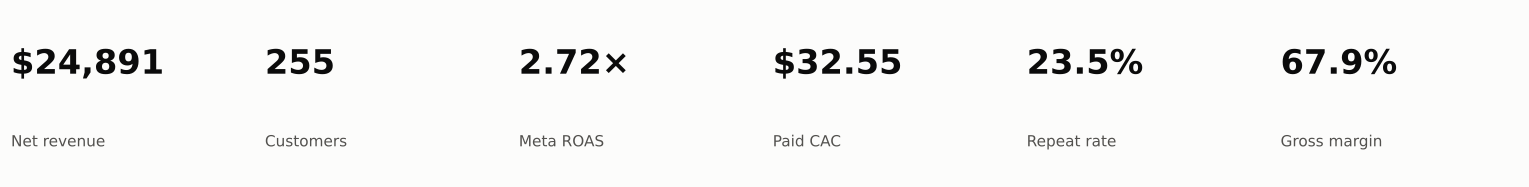

In [6]:
tiles = [("Net revenue", f"${kpi.net_revenue:,.0f}"), ("Customers", f"{kpi.unique_customers:,}"),
         ("Meta ROAS", f"{kpi.meta_roas:.2f}×"), ("Paid CAC", f"${kpi.paid_cac:,.2f}"),
         ("Repeat rate", f"{kpi.repeat_purchase_rate_pct:.1f}%"), ("Gross margin", f"{kpi.gross_margin_pct:.1f}%")]
fig, axes = plt.subplots(1, 6, figsize=(14, 1.8))
for ax, (label, val) in zip(axes, tiles):
    ax.axis("off")
    ax.text(0, 0.62, val, fontsize=22, fontweight="bold", color=INK, transform=ax.transAxes)
    ax.text(0, 0.18, label, fontsize=10, color=INK2, transform=ax.transAxes)
save(fig, "fig00_kpi_tiles")

**Read-out.** Over 14 months the brand did **≈ $24.9K net revenue from 255 customers and 341 orders** (AOV ≈ $73). Meta Ads returned **2.72× attributed ROAS**, well above the **≈ 1.63× break-even ROAS** set by the contribution margin on ad-driven orders (product, shipping and payment costs included). Counting all revenue, the blended marketing efficiency ratio (MER) is 4.7×.

## 3. Revenue trends

,month,orders,new_customers,net_revenue,new_customer_revenue,returning_customer_revenue,aov,ad_spend,meta_attributed_revenue,meta_roas,cogs_pct,profit_after_ads,cumulative_revenue,mom_growth_pct
0,2024-09,18,17,"1,560.00","1,466.00",94.00,86.67,469.65,986.40,2.10,30.80,506.21,"1,560.00",NaN
1,2024-10,20,17,"1,630.60","1,316.60",314.00,81.53,511.79,610.60,1.19,31.10,503.77,"3,190.60",4.50
2,2024-11,45,38,"3,023.90","2,567.00",456.90,67.20,544.32,"1,961.40",3.60,34.40,"1,267.37","6,214.50",85.40
3,2024-12,46,40,"3,762.70","3,081.30",681.40,81.80,600.52,"2,286.10",3.81,31.80,"1,703.13","9,977.20",24.40
4,2025-01,19,6,"1,544.10",549.60,994.50,81.27,172.39,"1,072.50",6.22,31.90,792.48,"11,521.30",-59.00
5,2025-02,13,4,892.20,198.00,694.20,68.63,207.58,412.00,1.98,31.30,354.83,"12,413.50",-42.20
6,2025-03,26,17,"1,602.60",903.40,699.20,61.64,355.10,995.00,2.80,31.60,666.94,"14,016.10",79.60
7,2025-04,21,14,"1,585.80","1,007.00",578.80,75.51,393.61,952.70,2.42,33.10,552.64,"15,601.90",-1.00
8,2025-05,14,8,914.90,488.20,426.70,65.35,395.49,560.00,1.42,31.00,184.41,"16,516.80",-42.30
9,2025-06,19,9,"1,002.30",454.80,547.50,52.75,440.36,472.00,1.07,30.60,212.88,"17,519.10",9.60


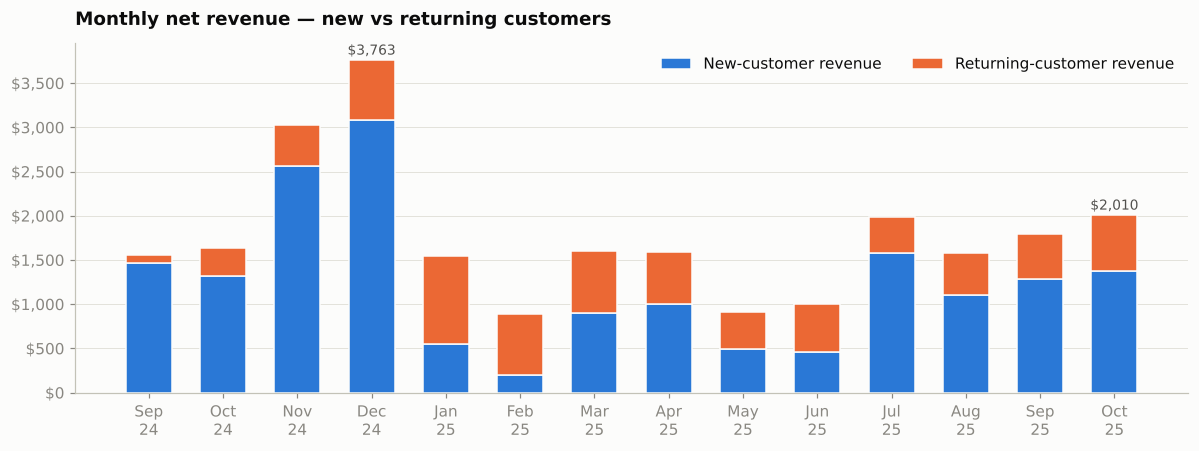

In [7]:
m = run_query("monthly_revenue_trend", con)
display(m)
x = np.arange(len(m)); labels = pd.to_datetime(m.month).dt.strftime("%b\n%y")
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(x, m.new_customer_revenue, width=0.62, color=BLUE, label="New-customer revenue", edgecolor=SURFACE, linewidth=1)
ax.bar(x, m.returning_customer_revenue, width=0.62, bottom=m.new_customer_revenue, color=ORANGE,
       label="Returning-customer revenue", edgecolor=SURFACE, linewidth=1)
for i in [m.net_revenue.idxmax(), len(m) - 1]:
    ax.text(x[i], m.net_revenue[i] + 60, f"${m.net_revenue[i]:,.0f}", ha="center", fontsize=9, color=INK2)
ax.set_xticks(x, labels); ax.yaxis.set_major_formatter(money); ax.grid(axis="x", visible=False)
ax.set_title("Monthly net revenue — new vs returning customers")
ax.legend(loc="upper right", ncols=2)
save(fig, "fig01_monthly_revenue")

**Read-out.**
- **Q4 is the engine.** Nov–Dec 2024 (BFCM + holiday gifting) produced **$6.8K, 27% of 14-month revenue in 2 months**.
- **The January–February cliff** (-59%, then -42%) coincides with ad spend dropping to ~$170–210/month; revenue in those months leaned on returning customers acquired in Q4.
- **Returning customers are a growing share** of each month: by mid-2025 roughly a quarter to a third of monthly revenue is repeat business.
- Product drops (Spring '25 in March, Summer in June–July, Fall '25 Zip Hoodie in September) create step-ups; summer pop-up (July) and late-summer promo (August) helped too.

## 4. Customer acquisition cost & customer value

,month,ad_spend,new_customers,meta_new_customers,paid_cac,blended_cac,pct_new_from_meta
0,2024-09,469.65,17,12,39.14,27.63,70.60
1,2024-10,511.79,18,11,46.53,28.43,61.10
2,2024-11,544.32,39,25,21.77,13.96,64.10
3,2024-12,600.52,43,28,21.45,13.97,65.10
4,2025-01,172.39,7,4,43.10,24.63,57.10
5,2025-02,207.58,4,3,69.19,51.90,75.00
6,2025-03,355.10,17,10,35.51,20.89,58.80
7,2025-04,393.61,14,11,35.78,28.12,78.60
8,2025-05,395.49,8,4,98.87,49.44,50.00
9,2025-06,440.36,9,4,110.09,48.93,44.40


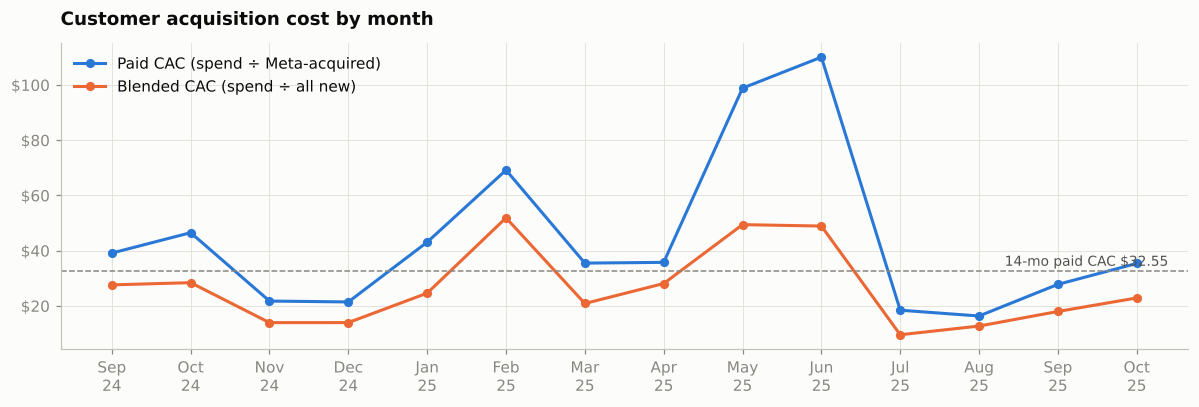

In [8]:
cac = run_query("customer_acquisition_cost", con)
display(cac)
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(cac)); labels = pd.to_datetime(cac.month).dt.strftime("%b\n%y")
ax.plot(x, cac.paid_cac, color=BLUE, lw=2, marker="o", ms=5, label="Paid CAC (spend ÷ Meta-acquired)")
ax.plot(x, cac.blended_cac, color=ORANGE, lw=2, marker="o", ms=5, label="Blended CAC (spend ÷ all new)")
ax.axhline(kpi.paid_cac, color=INK3, lw=1, ls="--")
ax.text(len(x) - 0.6, kpi.paid_cac + 2, f"14-mo paid CAC ${kpi.paid_cac:.2f}", ha="right", color=INK2, fontsize=9)
ax.set_xticks(x, labels); ax.yaxis.set_major_formatter(money); ax.legend(loc="upper left")
ax.set_title("Customer acquisition cost by month")
save(fig, "fig02_cac_trend")

,acquisition_channel,customers,pct_of_customers,repeat_rate_pct,avg_orders,avg_ltv_revenue,avg_ltv_contribution,cac,ltv_to_cac
0,Meta Ads,162,63.50,20.40,1.32,98.39,60.43,32.55,1.86
1,Instagram Organic,40,15.70,32.50,1.40,108.63,67.80,0.00,NaN
2,Referral,30,11.80,33.30,1.40,92.24,57.36,0.00,NaN
3,TikTok Organic,12,4.70,8.30,1.17,98.97,60.29,0.00,NaN
4,Pop-up Event,11,4.30,27.30,1.36,59.25,38.29,0.00,NaN


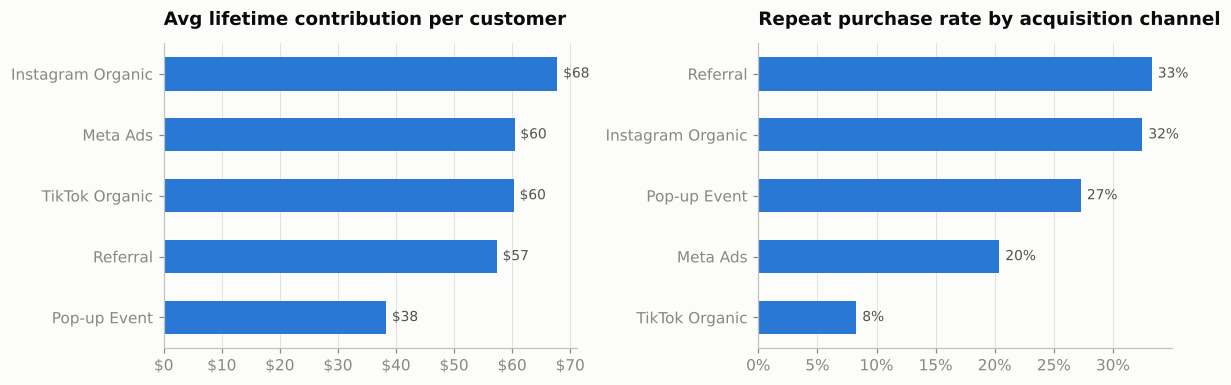

In [9]:
ch = run_query("cac_ltv_by_channel", con)
display(ch)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
order = ch.sort_values("avg_ltv_contribution")
axes[0].barh(order.acquisition_channel, order.avg_ltv_contribution, color=BLUE, height=0.55)
for y, v in enumerate(order.avg_ltv_contribution):
    axes[0].text(v + 1, y, f"${v:,.0f}", va="center", fontsize=9, color=INK2)
axes[0].xaxis.set_major_formatter(money); axes[0].grid(axis="y", visible=False)
axes[0].set_title("Avg lifetime contribution per customer")
order = ch.sort_values("repeat_rate_pct")
axes[1].barh(order.acquisition_channel, order.repeat_rate_pct, color=BLUE, height=0.55)
for y, v in enumerate(order.repeat_rate_pct):
    axes[1].text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=9, color=INK2)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[1].grid(axis="y", visible=False)
axes[1].set_title("Repeat purchase rate by acquisition channel")
save(fig, "fig03_channel_value")

**Read-out.**
- **Paid CAC averaged ≈ $33** (total Meta spend ÷ 162 Meta-acquired customers). It was lowest during BFCM/holiday and summer (≈ $16–22) and spiked to **$99–110 in May–June 2025**, the months the Brand Awareness campaign was running.
- A Meta-acquired customer generates **≈ $60 lifetime contribution vs a $33 CAC → LTV:CAC ≈ 1.9×** inside the observation window. That is profitable, but thin; it gets better only if more customers buy a second time.
- **Organic Instagram and referral customers are the most loyal** (≈ 30%+ repeat rates) and cost nothing in media. Meta-acquired customers repeat at ≈ 20%, so paid acquisition needs a strong post-purchase retention flow.

## 5. Advertising effectiveness (Meta)

In [10]:
camp = run_query("campaign_roas", con)
plan, s = reallocation_plan(con)
BE = s["breakeven_roas"]
acts = campaign_actions(camp, BE)
display(acts[["campaign_id", "campaign_name", "spend", "attributed_revenue", "roas", "cpm", "link_ctr_pct",
              "lpv_to_purchase_pct", "cost_per_new_customer", "profit_after_ad_spend", "action"]])

,campaign_id,campaign_name,spend,attributed_revenue,roas,cpm,link_ctr_pct,lpv_to_purchase_pct,cost_per_new_customer,profit_after_ad_spend,action
0,C05,VB | Retargeting | Site Visitors + ATC,866.23,"4,270.70",4.93,17.82,1.55,7.66,54.14,"1,783.88",Scale
1,C03,VB | BFCM 2024 | 25% Off,381.37,"1,576.90",4.13,16.64,1.14,11.11,18.16,525.13,Scale
2,C06,VB | Lookalike 1% | Purchasers,461.76,"1,574.40",3.41,12.04,1.12,7.18,17.10,546.09,Scale
3,C04,VB | Holiday Gifting 2024,262.43,771.60,2.94,13.83,0.89,8.89,21.87,215.45,Optimize & maintain
4,C08,VB | Summer Collection | Reels UGC,377.08,"1,061.20",2.81,8.46,1.04,3.99,25.14,273.35,Optimize & maintain
5,C10,VB | Fall Drop 2025 | Carousel,467.36,"1,192.00",2.55,12.37,0.84,5.14,35.95,260.39,Optimize & maintain
6,C02,VB | Interest | Streetwear Enthusiasts,819.47,"1,876.80",2.29,10.97,0.74,5.15,35.63,327.26,Optimize & maintain
7,C07,VB | Spring Drop 2025 | Video,265.37,509.20,1.92,11.42,0.58,9.01,26.54,36.78,Cut / restructure
8,C01,VB | Launch | Broad Prospecting,732.43,"1,217.00",1.66,9.26,0.58,4.30,45.78,45.23,Cut / restructure
9,C09,VB | Brand Awareness | Reach,639.99,294.00,0.46,4.94,0.30,0.94,213.33,-464.92,Cut / restructure


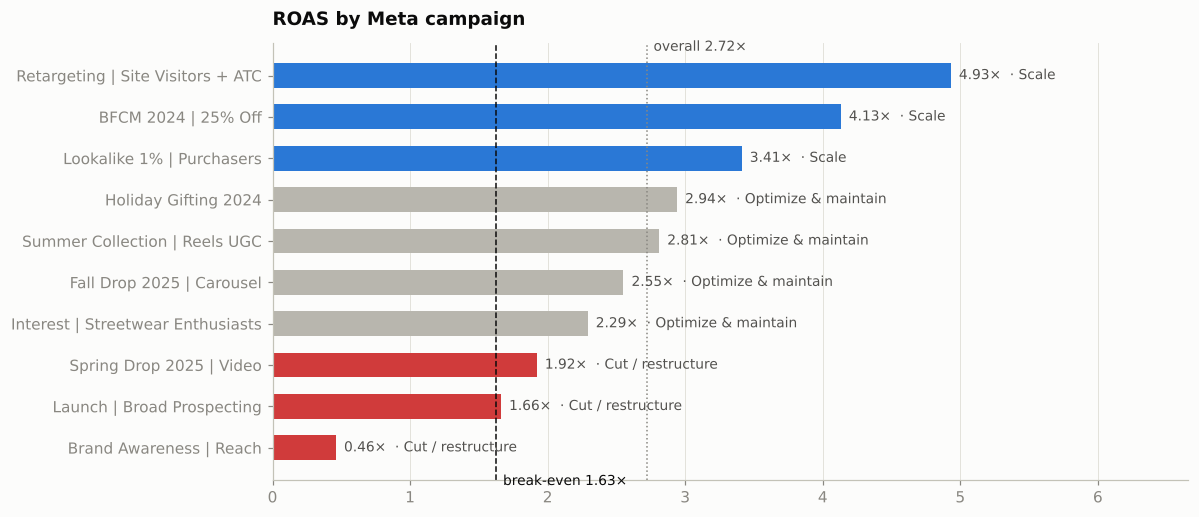

In [11]:
d = acts.sort_values("roas")
col = d.action.map({"Scale": BLUE, "Optimize & maintain": MUTED, "Cut / restructure": CRITICAL})
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh(d.campaign_name.str.replace("VB | ", "", regex=False), d.roas, color=col, height=0.6)
for y, (r, a) in enumerate(zip(d.roas, d.action)):
    ax.text(r + 0.06, y, f"{r:.2f}×  · {a}", va="center", fontsize=9, color=INK2)
ax.axvline(BE, color=INK, lw=1, ls="--")
ax.text(BE + 0.05, -0.9, f"break-even {BE:.2f}×", fontsize=9, color=INK)
ax.axvline(kpi.meta_roas, color=INK3, lw=1, ls=":")
ax.text(kpi.meta_roas + 0.05, len(d) - 0.4, f"overall {kpi.meta_roas:.2f}×", fontsize=9, color=INK2)
ax.set_xlim(0, d.roas.max() * 1.35); ax.grid(axis="y", visible=False)
ax.set_title("ROAS by Meta campaign")
save(fig, "fig04_campaign_roas")

,dimension,value,campaigns,spend,attributed_revenue,roas,cost_per_purchase,profit_after_ad_spend
0,strategy,Retargeting,1,866.23,"4,270.70",4.93,17.68,"1,783.88"
1,strategy,Seasonal Promotion,2,643.80,"2,348.50",3.65,18.39,740.58
2,strategy,Lookalike Prospecting,1,461.76,"1,574.40",3.41,17.10,546.09
3,strategy,UGC / Reels,1,377.08,"1,061.20",2.81,25.14,273.35
4,strategy,Product Drop,2,732.73,"1,701.20",2.32,31.86,297.17
5,strategy,Interest Prospecting,1,819.47,"1,876.80",2.29,35.63,327.26
6,strategy,Broad Prospecting,1,732.43,"1,217.00",1.66,45.78,45.23
7,strategy,Brand Awareness,1,639.99,294.00,0.46,213.33,-464.92
8,creative_type,Dynamic Product Ads,1,866.23,"4,270.70",4.93,17.68,"1,783.88"
9,creative_type,UGC Video,1,461.76,"1,574.40",3.41,17.10,546.09


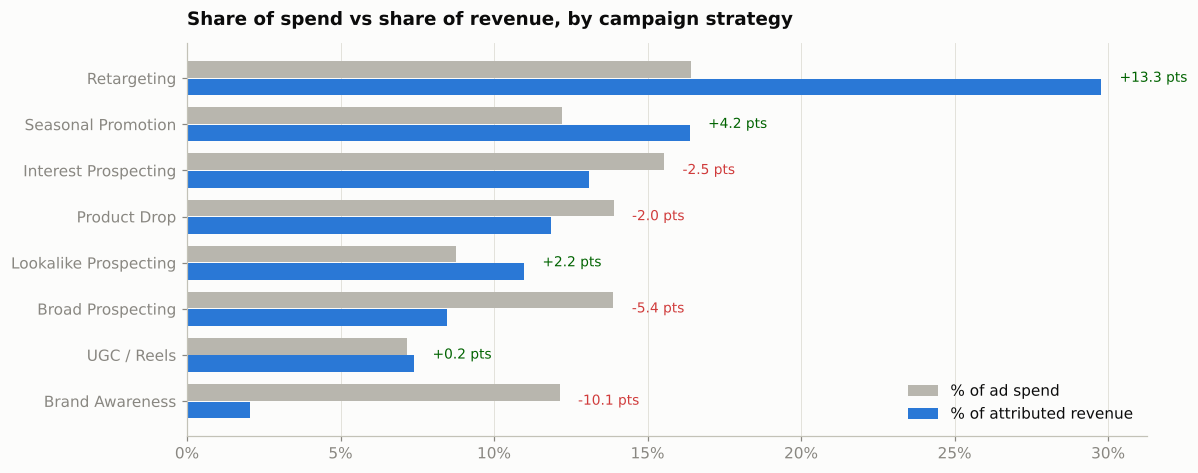

In [12]:
strat = run_query("roas_by_strategy_creative", con)
display(strat)
st = sql("SELECT strategy, SUM(spend) spend, SUM(purchase_value) rev FROM v_campaign_performance GROUP BY strategy", con)
st["spend_pct"] = 100 * st.spend / st.spend.sum(); st["rev_pct"] = 100 * st.rev / st.rev.sum()
st = st.sort_values("rev_pct")
y = np.arange(len(st))
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.barh(y + 0.19, st.spend_pct, height=0.36, color=MUTED, label="% of ad spend")
ax.barh(y - 0.19, st.rev_pct, height=0.36, color=BLUE, label="% of attributed revenue")
for yy, a, b in zip(y, st.spend_pct, st.rev_pct):
    ax.text(max(a, b) + 0.6, yy, f"{b - a:+.1f} pts", va="center", fontsize=9,
            color="#006300" if b >= a else CRITICAL)
ax.set_yticks(y, st.strategy); ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
ax.set_title("Share of spend vs share of revenue, by campaign strategy")
save(fig, "fig05_spend_vs_revenue_share")

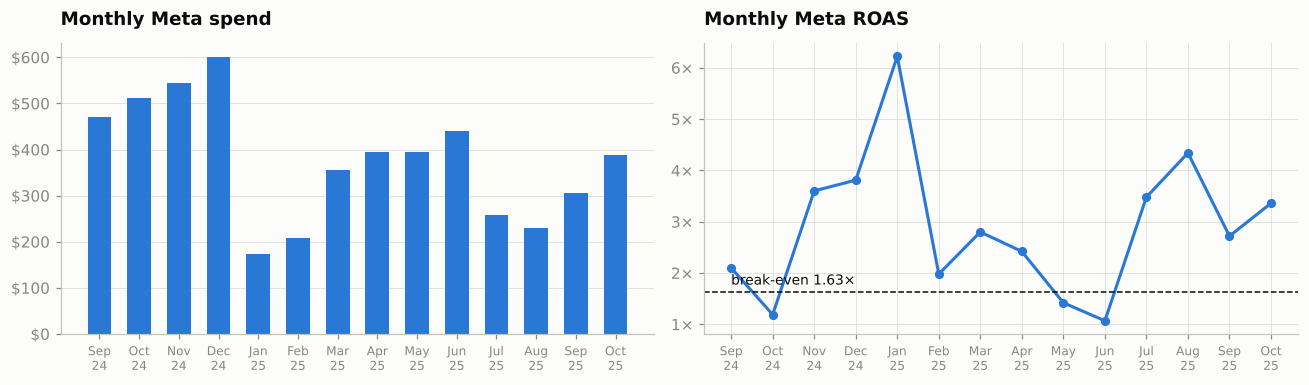

In [13]:
mt = m.copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
x = np.arange(len(mt)); labels = pd.to_datetime(mt.month).dt.strftime("%b\n%y")
axes[0].bar(x, mt.ad_spend, color=BLUE, width=0.6)
axes[0].set_xticks(x, labels, fontsize=8); axes[0].yaxis.set_major_formatter(money); axes[0].grid(axis="x", visible=False)
axes[0].set_title("Monthly Meta spend")
axes[1].plot(x, mt.meta_roas, color=BLUE, lw=2, marker="o", ms=5)
axes[1].axhline(BE, color=INK, lw=1, ls="--"); axes[1].text(0, BE + 0.15, f"break-even {BE:.2f}×", fontsize=9)
axes[1].set_xticks(x, labels, fontsize=8); axes[1].set_title("Monthly Meta ROAS")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.0f}×"))
save(fig, "fig06_monthly_spend_roas")

In [14]:
fun = sql('''SELECT strategy, SUM(impressions) impressions, SUM(link_clicks) link_clicks,
                    SUM(landing_page_views) lpv, SUM(add_to_cart) atc, SUM(purchases) purchases
             FROM v_campaign_performance GROUP BY strategy''', con)
fun["CTR %"] = 100 * fun.link_clicks / fun.impressions
fun["LPV→ATC %"] = 100 * fun.atc / fun.lpv
fun["ATC→Purchase %"] = 100 * fun.purchases / fun.atc
display(fun.sort_values("ATC→Purchase %", ascending=False))

,strategy,impressions,link_clicks,lpv,atc,purchases,CTR %,LPV→ATC %,ATC→Purchase %
6,Seasonal Promotion,41905,430,342,49,35,1.03,14.33,71.43
4,Product Drop,61030,454,364,39,23,0.74,10.71,58.97
3,Lookalike Prospecting,38364,431,376,47,27,1.12,12.50,57.45
7,UGC / Reels,44557,464,376,36,15,1.04,9.57,41.67
2,Interest Prospecting,74730,554,447,56,23,0.74,12.53,41.07
5,Retargeting,48619,756,640,120,49,1.55,18.75,40.83
1,Broad Prospecting,79136,457,372,46,16,0.58,12.37,34.78
0,Brand Awareness,129566,392,319,21,3,0.30,6.58,14.29


**Read-out.**
- **Top campaigns:** *Retargeting – Site Visitors + ATC* (**4.93×**, 30% of attributed revenue on 16% of spend), *BFCM 2024* (**4.13×**) and *Lookalike 1% – Purchasers* with UGC video (**3.41×**, the most efficient way to find *new* customers at ≈ $17 per new customer).
- **Bottom campaigns:** *Brand Awareness – Reach* (**0.46×**, $640 spent for 3 purchases, ≈ $213 per customer), *Launch – Broad Prospecting* (**1.66×**, at break-even) and *Spring Drop – Studio Video* (**1.92×**). Those three took **31% of spend and returned 14% of attributed revenue**.
- **Creative matters as much as audience:** UGC formats (video + Reels) delivered ≈ 3.1× while polished studio video returned 0.9×. Reels UGC also had the cheapest CPM ($8.46).
- Monthly ROAS dipped below break-even in **Oct 2024** (broad launch campaign fatiguing) and **May–June 2025** (awareness spend).

## 6. Customer retention

In [15]:
rep = run_query("repeat_purchase_rate", con)
display(rep)
curve = run_query("cumulative_retention_curve", con)
display(curve)
coh = run_query("cohort_retention", con)
piv = coh.pivot(index="cohort_month", columns="months_since_first", values="retention_pct").fillna(0)
size = coh.groupby("cohort_month").cohort_customers.first()
piv = piv.drop(columns=0)
# blank out cells that are not yet observable
n_months = len(piv)
mask = np.array([[c > n_months - 1 - i for c in piv.columns] for i in range(n_months)])

,orders_bucket,customers,pct_customers,overall_repeat_rate_pct,avg_days_to_2nd_order,customers_with_2nd_order
0,1,191,76.10,23.50,59.00,66
1,2,38,15.10,23.50,59.00,66
2,3,15,6.00,23.50,59.00,66
3,4+,7,2.80,23.50,59.00,66


,window_days,eligible_customers,repurchased,repeat_rate_pct
0,30,238,12,5.00
1,60,222,40,18.00
2,90,203,48,23.60
3,120,177,49,27.70
4,180,160,48,30.00
5,270,124,39,31.50
6,365,35,13,37.10


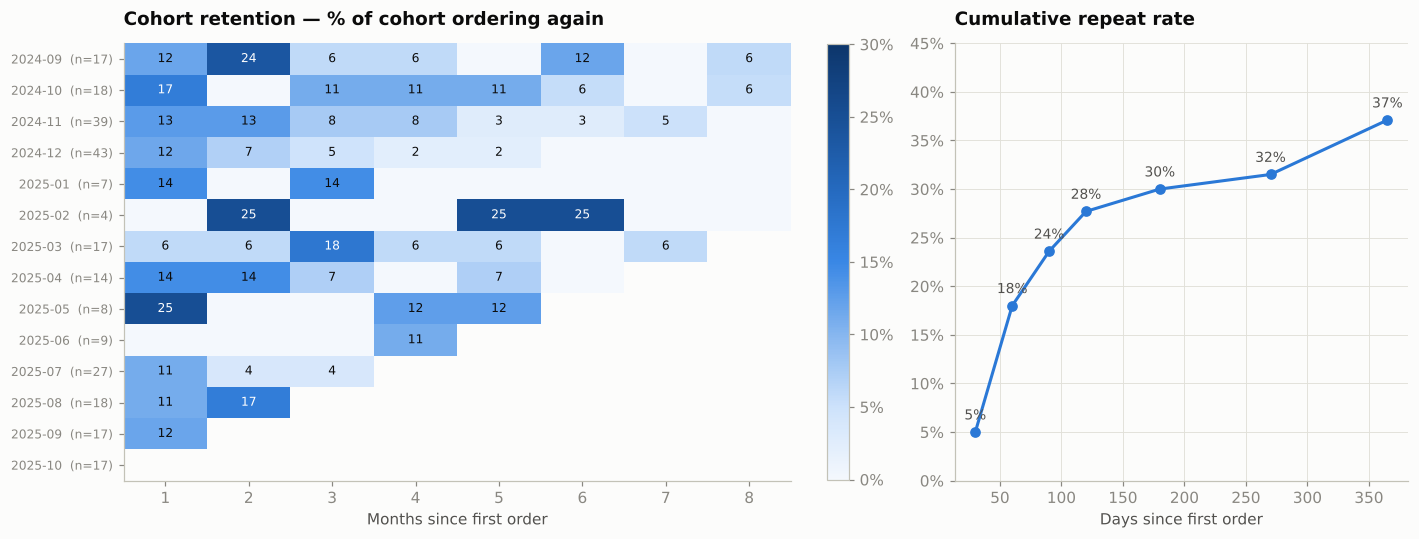

In [16]:
from matplotlib.colors import LinearSegmentedColormap
seq = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
data = np.ma.masked_array(piv.values, mask=mask)
im = ax.imshow(data, cmap=seq, vmin=0, vmax=30, aspect="auto")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        if not mask[i, j] and piv.values[i, j] > 0:
            v = piv.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 15 else INK)
ax.set_xticks(range(piv.shape[1]), piv.columns); ax.set_yticks(range(len(piv)), [f"{c}  (n={size[c]})" for c in piv.index], fontsize=8)
ax.set_xlabel("Months since first order"); ax.grid(False)
ax.set_title("Cohort retention — % of cohort ordering again")
fig.colorbar(im, ax=ax, fraction=0.03, format=mtick.PercentFormatter(decimals=0))
ax = axes[1]
ax.plot(curve.window_days, curve.repeat_rate_pct, color=BLUE, lw=2, marker="o", ms=6)
for xx, yy, n in zip(curve.window_days, curve.repeat_rate_pct, curve.eligible_customers):
    ax.text(xx, yy + 1.3, f"{yy:.0f}%", ha="center", fontsize=9, color=INK2)
ax.set_ylim(0, 45); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Days since first order"); ax.set_title("Cumulative repeat rate")
save(fig, "fig07_retention")

In [17]:
nr = run_query("new_vs_returning_and_discounts", con)
display(nr)

,order_type,discount_code,orders,net_revenue,aov,discount_given,contribution_margin_pct
0,First order,(none),180,"12,722.00",70.68,0.00,62.90
1,First order,WELCOME10,40,"3,078.00",76.95,342.00,60.80
2,First order,BFCM25,24,"1,522.50",63.44,507.50,54.70
3,First order,SUMMER20,2,51.20,25.60,12.80,63.70
4,Repeat order,(none),70,"5,710.00",81.57,0.00,62.60
5,Repeat order,VIP15,22,"1,672.80",76.04,295.20,58.10
6,Repeat order,SUMMER20,2,105.60,52.80,26.40,54.60
7,Repeat order,BFCM25,1,28.50,28.50,9.50,61.80


**Read-out.**
- **23.5% of customers have bought more than once** (60 of 255); 9% have bought 3+ times. The average customer places 1.34 orders.
- **The second purchase happens fast or not at all:** average gap to the 2nd order ≈ 59 days; the cumulative repeat rate climbs from 5% at 30 days to **≈ 24% at 90 days**, then flattens near 30% by day 180 (the 365-day point rests on only 35 customers old enough to measure). The **30–90 day window is when retention marketing has to happen**.
- **Retention is front-loaded:** most cohorts post their best re-purchase rate in months 1–2 (typically 11–17%) and taper to low single digits by month 4–5. The large Q4 cohorts (82 customers, many acquired on BFCM25) re-buy at 12–13% in month 1 and fade to 2–8% by months 3–5 — the holiday surge needs a deliberate Q1 win-back.
- Discounts are not the main lever: 73% of first orders were full price, and VIP15 repeat orders carry lower contribution margin (58%) than full-price repeats (63%).

## 7. Product profitability

In [18]:
pm = run_query("product_margins", con)
display(pm)
cat = run_query("category_margins", con)
display(cat)

,product_id,product_name,category,collection,retail_price,unit_cost,list_margin_pct,units_sold,orders,net_revenue,cogs,gross_profit,realized_margin_pct,pct_of_revenue,gross_profit_per_30_days_live,profit_rank
0,P04,Signature Heavyweight Hoodie - Black,Hoodies,Core,78.00,24.00,69.20,77,72,"5,647.20","1,848.00","3,799.20",67.30,22.70,267.55,1
1,P07,Signature Sweatpants,Bottoms,Core,62.00,19.00,69.30,46,43,"2,746.60",874.00,"1,872.60",68.20,11.00,131.87,2
2,P05,Signature Heavyweight Hoodie - Cream,Hoodies,Core,78.00,24.00,69.20,35,35,"2,640.30",840.00,"1,800.30",68.20,10.60,136.39,3
3,P03,Visionary Graphic Tee,Tees,Core,38.00,11.00,71.00,62,60,"2,261.00",682.00,"1,579.00",69.80,9.10,111.20,4
4,P06,Beyond Crewneck,Crewnecks,Fall/Winter 2024,64.00,19.50,69.50,38,36,"2,233.60",741.00,"1,492.60",66.80,9.00,117.22,5
5,P01,Essential Logo Tee - Black,Tees,Core,32.00,9.50,70.30,64,61,"1,944.00",608.00,"1,336.00",68.70,7.80,94.08,6
6,P02,Essential Logo Tee - White,Tees,Core,32.00,9.50,70.30,62,57,"1,843.20",589.00,"1,254.20",68.00,7.40,88.32,7
7,P08,Embroidered Dad Hat,Accessories,Core,28.00,7.00,75.00,38,38,"1,033.20",266.00,767.20,74.30,4.20,54.03,8
8,P15,Fall '25 Zip Hoodie,Hoodies,Fall 2025,84.00,27.00,67.90,11,11,911.40,297.00,614.40,67.40,3.70,323.37,9
9,P09,Knit Beanie,Accessories,Fall/Winter 2024,24.00,6.50,72.90,32,30,751.20,208.00,543.20,72.30,3.00,44.65,10


,category,skus,units_sold,net_revenue,gross_profit,margin_pct,avg_net_price,pct_of_revenue
0,Hoodies,3,123,"9,198.90","6,213.90",67.60,74.79,37.00
1,Tees,5,227,"7,405.40","5,107.90",69.00,32.62,29.80
2,Bottoms,2,64,"3,446.60","2,347.60",68.10,53.85,13.80
3,Crewnecks,1,38,"2,233.60","1,492.60",66.80,58.78,9.00
4,Accessories,3,76,"1,910.90","1,382.90",72.40,25.14,7.70
5,Outerwear,1,8,695.20,351.20,50.50,86.90,2.80


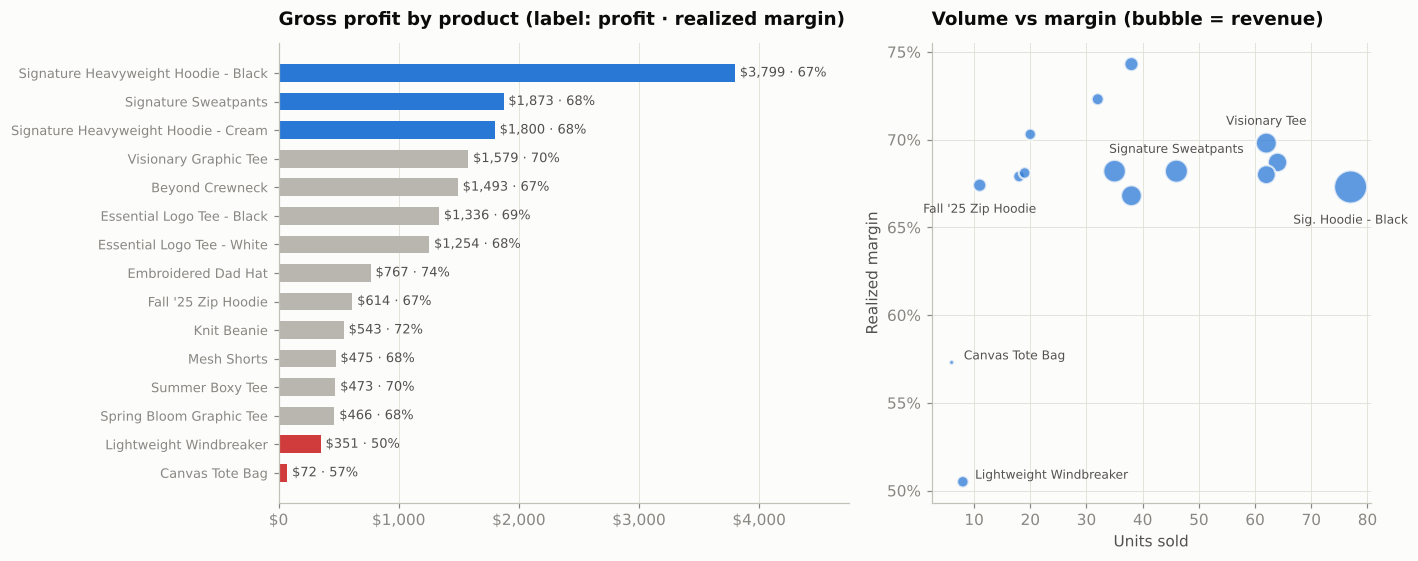

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
d = pm.sort_values("gross_profit")
ax = axes[0]
colors = [BLUE if r <= 3 else (CRITICAL if mp < 60 else MUTED) for r, mp in zip(d.profit_rank, d.realized_margin_pct)]
ax.barh(d.product_name, d.gross_profit, color=colors, height=0.62)
for yy, (gp, mp) in enumerate(zip(d.gross_profit, d.realized_margin_pct)):
    ax.text(gp + 40, yy, f"${gp:,.0f} · {mp:.0f}%", va="center", fontsize=8.5, color=INK2)
ax.xaxis.set_major_formatter(money); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
ax.set_xlim(0, d.gross_profit.max() * 1.25)
ax.set_title("Gross profit by product (label: profit · realized margin)")
ax = axes[1]
ax.scatter(pm.units_sold, pm.realized_margin_pct, s=pm.net_revenue / 12, color=BLUE, alpha=0.75,
           edgecolor=SURFACE, linewidth=1.5)
offsets = {"P04": (0, -24), "P07": (0, 12), "P03": (0, 12), "P15": (0, -18), "P11": (8, 2), "P14": (8, 2)}
for _, r in pm[pm.product_id.isin(offsets)].iterrows():
    dx, dy = offsets[r.product_id]
    ax.annotate(r.product_name.replace("Signature Heavyweight ", "Sig. ").replace(" Graphic", ""),
                (r.units_sold, r.realized_margin_pct), xytext=(dx, dy), textcoords="offset points",
                fontsize=8, color=INK2, ha="center" if dx == 0 else "left")
ax.set_xlabel("Units sold"); ax.set_ylabel("Realized margin")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Volume vs margin (bubble = revenue)")
save(fig, "fig08_product_profitability")

**Read-out.**
- **The Signature Heavyweight Hoodie is the business.** Black + Cream together generated **$8.3K net revenue (33%) and $5.6K gross profit**. Add Signature Sweatpants (#2 by profit) and the "Signature" line is **≈ 44% of revenue**.
- **Hoodies are the most valuable category** ($6.2K gross profit, 37% of revenue at a 68% margin); tees move the most units (227) but at ~$33 average price.
- **Fall '25 Zip Hoodie is the fastest earner per month live** (≈ $323 gross profit / 30 days, vs $268 for the Black Signature Hoodie) — an early signal worth backing with ad spend.
- **Margin laggards:** the *Lightweight Windbreaker* (51% margin, 8 units) and *Canvas Tote* (57%, 6 units) tie up inventory dollars for little profit.

## 8. Top performers & ad budget reallocation

In [20]:
top = run_query("top_products_by_campaign", con)
display(top[top.campaign_id.isin(["C05", "C06", "C03", "C08"])])

,campaign_id,campaign_name,product_rank,product_name,units,net_revenue
6,C03,VB | BFCM 2024 | 25% Off,1,Signature Heavyweight Hoodie - Black,8,487.50
7,C03,VB | BFCM 2024 | 25% Off,2,Beyond Crewneck,6,310.40
8,C03,VB | BFCM 2024 | 25% Off,3,Signature Sweatpants,4,217.00
12,C05,VB | Retargeting | Site Visitors + ATC,1,Signature Heavyweight Hoodie - Black,12,912.60
13,C05,VB | Retargeting | Site Visitors + ATC,2,Signature Sweatpants,12,734.70
14,C05,VB | Retargeting | Site Visitors + ATC,3,Essential Logo Tee - White,15,448.00
15,C06,VB | Lookalike 1% | Purchasers,1,Signature Heavyweight Hoodie - Cream,6,460.20
16,C06,VB | Lookalike 1% | Purchasers,2,Essential Logo Tee - White,5,156.80
17,C06,VB | Lookalike 1% | Purchasers,3,Essential Logo Tee - Black,5,153.60
21,C08,VB | Summer Collection | Reels UGC,1,Summer Boxy Tee,8,265.20


In [21]:
print(f"Break-even ROAS = 1 / contribution-margin rate ({s['contribution_margin_rate']:.1%}) = {s['breakeven_roas']:.2f}x")
print(f"Forward budget (historic monthly average x {s['months']}): ${s['budget']:,.0f}")
display(plan)
print(f"Projected attributed revenue: ${s['current_revenue']:,.0f} -> ${s['projected_revenue']:,.0f} "
      f"(+{s['projected_revenue']/s['current_revenue']-1:.0%})")
print(f"Projected ROAS: {s['current_roas']:.2f}x -> {s['projected_roas']:.2f}x")
print(f"Projected profit after ad spend: ${s['current_profit']:,.0f} -> ${s['projected_profit']:,.0f} "
      f"(+{s['projected_profit']/s['current_profit']-1:.0%})")

Break-even ROAS = 1 / contribution-margin rate (61.5%) = 1.63x
Forward budget (historic monthly average x 12): $4,520


,strategy,roas,current_share,current_budget,proposed_share,proposed_budget,budget_change,current_revenue,projected_revenue,projected_roas,current_profit,projected_profit
0,Retargeting,4.93,0.16,742.48,0.24,"1,084.83",342.35,"3,660.60","4,773.38",4.40,"1,508.96","1,851.02"
1,Lookalike Prospecting,3.41,0.09,395.79,0.22,994.43,598.64,"1,349.49","2,571.83",2.59,434.20,587.37
2,Seasonal Promotion,3.65,0.12,551.83,0.18,813.62,261.80,"2,013.00","2,641.66",3.25,686.26,811.13
3,UGC / Reels,2.81,0.07,323.21,0.18,813.62,490.41,909.60,"1,735.83",2.13,236.24,253.99
4,Product Drop,2.32,0.14,628.05,0.10,452.01,-176.04,"1,458.17","1,049.45",2.32,268.79,193.45
5,Interest Prospecting,2.29,0.16,702.40,0.08,361.61,-340.79,"1,608.69",828.18,2.29,287.02,147.76
6,Brand Awareness,0.46,0.12,548.56,0.00,0.00,-548.56,252.00,0.00,NaN,-393.57,0.00
7,Broad Prospecting,1.66,0.14,627.80,0.00,0.00,-627.80,"1,043.14",0.00,NaN,13.79,0.00


Projected attributed revenue: $12,295 -> $13,600 (+11%)
Projected ROAS: 2.72x -> 3.01x
Projected profit after ad spend: $3,042 -> $3,845 (+26%)


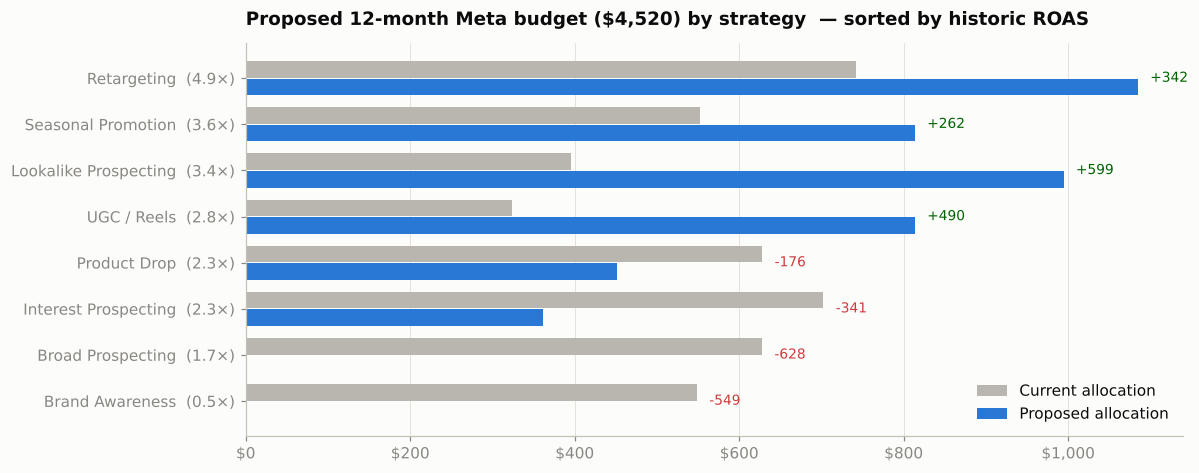

In [22]:
d = plan.sort_values("roas")
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.barh(y + 0.19, d.current_budget, height=0.36, color=MUTED, label="Current allocation")
ax.barh(y - 0.19, d.proposed_budget, height=0.36, color=BLUE, label="Proposed allocation")
for yy, a, b in zip(y, d.current_budget, d.proposed_budget):
    ax.text(max(a, b) + 15, yy, f"{b - a:+,.0f}", va="center", fontsize=9, color="#006300" if b >= a else CRITICAL)
ax.set_yticks(y, [f"{st}  ({r:.1f}×)" for st, r in zip(d.strategy, d.roas)])
ax.xaxis.set_major_formatter(money); ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
ax.set_title(f"Proposed 12-month Meta budget (${s['budget']:,.0f}) by strategy  — sorted by historic ROAS")
save(fig, "fig09_budget_reallocation")

### Budget reallocation logic

* **Budget held flat** at the historic run-rate (≈ $377/month → ≈ $4.5K over 12 months) so the gain comes purely from *where* money goes.
* **Cuts** lose revenue at each strategy's historic ROAS (conservative — real marginal ROAS on the last dollars of a weak campaign is usually *below* its average).
* **Increases** earn revenue on a concave response curve, revenue ∝ spend^0.7, to reflect audience saturation and rising frequency. Retargeting is capped at +60% because its warm audience is finite.
* **Profit after ads** = revenue × contribution-margin rate (61%) − spend.

Result: the same budget is projected to return **≈ +11% attributed revenue, ROAS 2.72× → ≈ 3.0×, and ≈ +26% profit after ad spend**.

## 9. Dashboard preview

A static preview of the Tableau dashboard layout (built in Tableau from `tableau/data/` — see `tableau/DASHBOARD_GUIDE.md`).

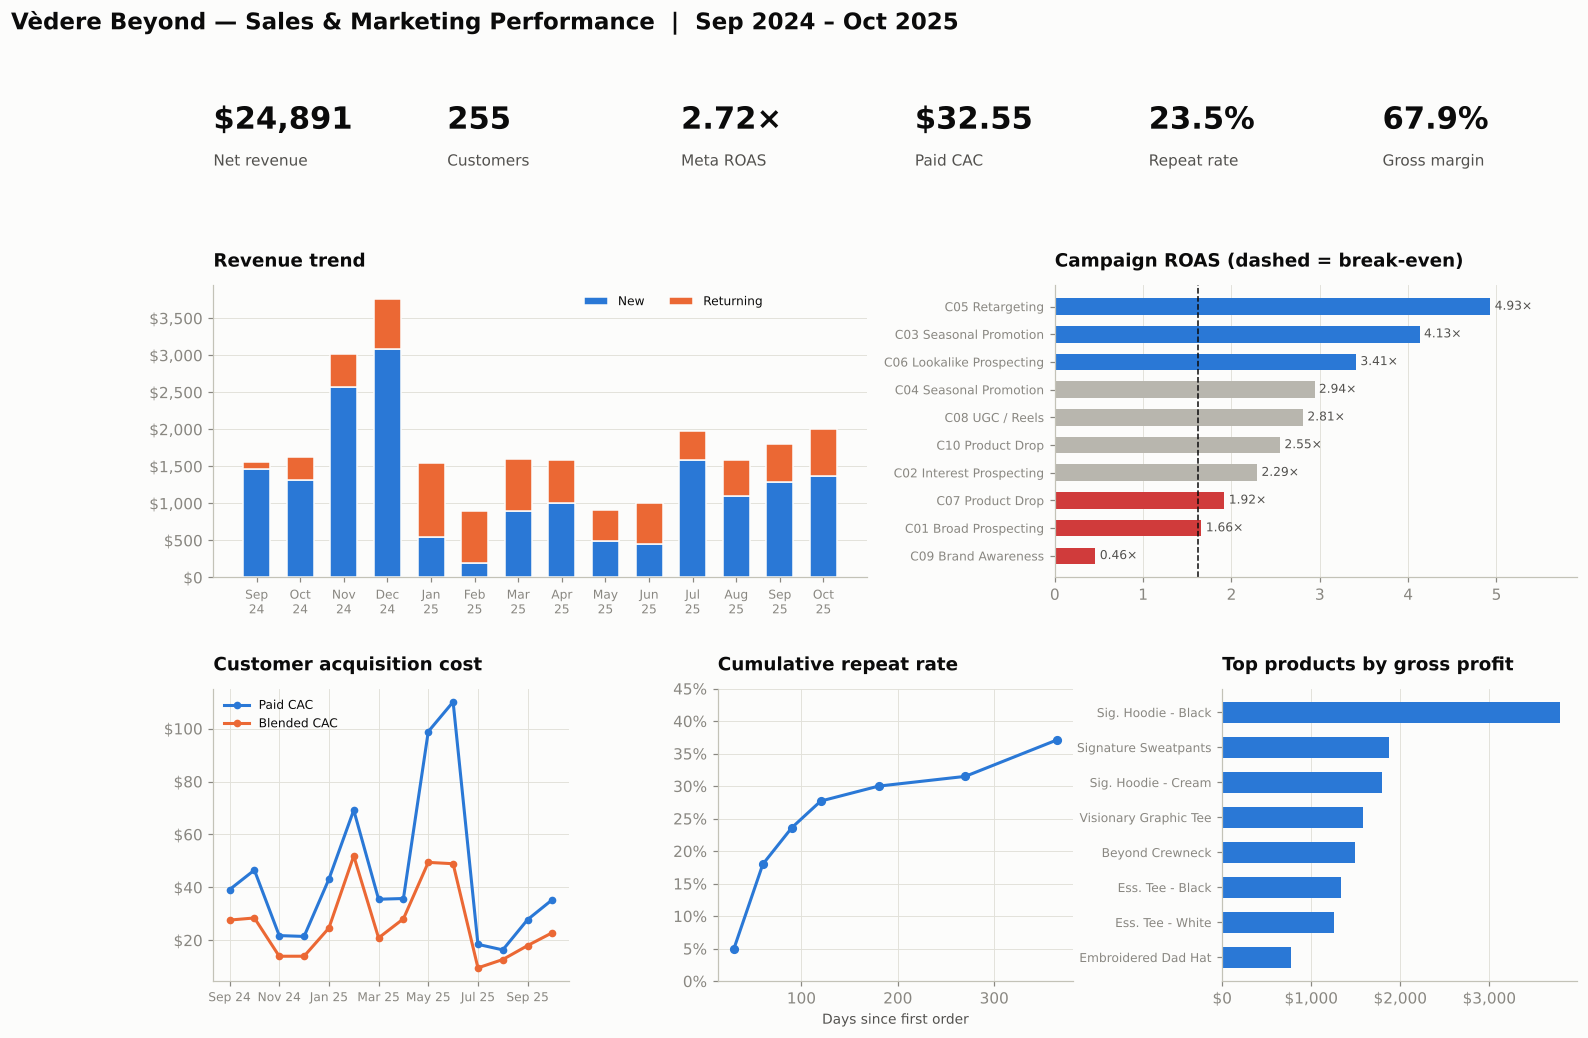

In [23]:
fig = plt.figure(figsize=(16, 10.5))
gs = fig.add_gridspec(3, 6, height_ratios=[0.28, 1, 1], hspace=0.5)
row1 = gs[1, :].subgridspec(1, 2, width_ratios=[1.25, 1], wspace=0.32)
row2 = gs[2, :].subgridspec(1, 3, wspace=0.42)
fig.suptitle("Vèdere Beyond — Sales & Marketing Performance  |  Sep 2024 – Oct 2025", x=0.01, y=0.95, ha="left",
             fontsize=15, fontweight="bold")
for i, (label, val) in enumerate(tiles):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.text(0, 0.55, val, fontsize=20, fontweight="bold", transform=ax.transAxes)
    ax.text(0, 0.1, label, fontsize=10, color=INK2, transform=ax.transAxes)
# revenue trend
ax = fig.add_subplot(row1[0]); x = np.arange(len(m))
ax.bar(x, m.new_customer_revenue, color=BLUE, width=0.62, label="New", edgecolor=SURFACE)
ax.bar(x, m.returning_customer_revenue, bottom=m.new_customer_revenue, color=ORANGE, width=0.62, label="Returning", edgecolor=SURFACE)
ax.set_xticks(x, pd.to_datetime(m.month).dt.strftime("%b\n%y"), fontsize=8); ax.yaxis.set_major_formatter(money)
ax.grid(axis="x", visible=False); ax.legend(loc="upper left", bbox_to_anchor=(0.55, 1.0), ncols=2, fontsize=8); ax.set_title("Revenue trend")
# campaign ROAS
ax = fig.add_subplot(row1[1]); d = acts.sort_values("roas")
ax.barh(d.campaign_id + " " + d.strategy, d.roas, height=0.6,
        color=d.action.map({"Scale": BLUE, "Optimize & maintain": MUTED, "Cut / restructure": CRITICAL}))
ax.axvline(BE, color=INK, lw=1, ls="--"); ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
ax.set_xlim(0, d.roas.max() * 1.2)
for yy, r in enumerate(d.roas): ax.text(r + 0.05, yy, f"{r:.2f}×", va="center", fontsize=8, color=INK2)
ax.set_title("Campaign ROAS (dashed = break-even)")
# CAC
ax = fig.add_subplot(row2[0]); x = np.arange(len(cac))
ax.plot(x, cac.paid_cac, color=BLUE, lw=2, marker="o", ms=4, label="Paid CAC")
ax.plot(x, cac.blended_cac, color=ORANGE, lw=2, marker="o", ms=4, label="Blended CAC")
ax.set_xticks(x[::2], pd.to_datetime(cac.month).dt.strftime("%b %y")[::2], fontsize=8)
ax.yaxis.set_major_formatter(money); ax.legend(fontsize=8); ax.set_title("Customer acquisition cost")
# retention curve
ax = fig.add_subplot(row2[1])
ax.plot(curve.window_days, curve.repeat_rate_pct, color=BLUE, lw=2, marker="o", ms=5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylim(0, 45)
ax.set_xlabel("Days since first order", fontsize=9); ax.set_title("Cumulative repeat rate")
# product profit
ax = fig.add_subplot(row2[2]); d = pm.head(8).sort_values("gross_profit")
ax.barh(d.product_name.str.replace("Signature Heavyweight ", "Sig. ").str.replace("Essential Logo ", "Ess. "),
        d.gross_profit, color=BLUE, height=0.6)
ax.xaxis.set_major_formatter(money); ax.xaxis.set_major_locator(mtick.MaxNLocator(4))
ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
ax.set_title("Top products by gross profit")
fig.savefig(FIG / "dashboard_preview.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Recommendations

**Advertising budget (same total spend, projected +11% attributed revenue, ROAS ≈ 3.0×)**
1. **Pause Brand Awareness / Reach** (0.46×) and **Broad Prospecting** (1.66× ≈ break-even). Move that ≈ 26% of budget into the three proven engines below.
2. **Scale Lookalike 1% of purchasers with UGC video** from 9% → 22% of budget — it finds *new* customers at ≈ $17 each, half the account-average CAC.
3. **Grow UGC / Reels** from 7% → 18%: cheapest CPM in the account and 2.8× ROAS. Commission 3–4 new UGC creators per drop and retire polished studio video (0.9× across two campaigns).
4. **Raise always-on Retargeting** from 16% → 24% (capped by audience size), feeding it with dynamic product ads featuring the Signature Hoodie and Sweatpants.
5. **Concentrate seasonal promotion on BFCM / holiday** (18% of budget, ≈ 3.7× historically). Pre-load Oct–Nov with lookalike prospecting so retargeting pools are full when the sale starts.
6. **Product drops**: keep, but launch with carousel + UGC rather than studio video, and put the Fall '25 Zip Hoodie (best profit-per-month-live) at the front of fall creative.

**Retention**
7. Build a **30/60/90-day post-purchase flow** (email + SMS): the repeat curve rises from 5% at day 30 to 24% at day 90 and only reaches 30% by day 180, so the second purchase is won or lost in the first 90 days. Lifting the 90-day repeat rate from 24% to 30% would add ≈ 15 repeat orders per 250 new customers.
8. Move discounting from blanket VIP15 to a **cross-sell offer** (hoodie buyers → sweatpants "complete the set"), protecting margin.

**Product**
9. Treat the **Signature Heavyweight line as the hero**: keep core colorways in stock, test a third colorway, and build bundles around it.
10. **Discontinue or re-cost the Windbreaker and Canvas Tote** (51% and 57% margin, < 10 units each); use the tote as a free-gift-with-purchase threshold item instead.

## 11. Limitations
* Data is synthetic and calibrated to real totals; campaign-level and product-level splits are simulated.
* Meta attribution (7-day click / 1-day view) over-credits retargeting, which partly harvests demand from customers who would have bought anyway. Run a **holdout / conversion-lift test** before scaling retargeting further.
* The response-curve elasticity (0.7) is an assumption; validate it with staged budget increases (e.g. +25% for 3 weeks) rather than one large jump.
* LTV is observed (not predicted) and censored for recent cohorts, so it understates long-run value.

In [24]:
con.close()